# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [3]:
# PLIK_LODZ = "przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv"
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [4]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [5]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ, sep=";")

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print(df.head())
print(df.shape)
df.info()

                 name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie
(65, 4)
<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   name     65 non-null     str  
 1   rok      65 non-null     int64
 2   wartość  65 non-null     int64
 3   zmienna  65 non-null     str  
dtypes: int64(2), str(2)
memory usage: 2.2 KB


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* separatorem jest średnik, kolumna `wartość` ma typ liczbowy, nazwy kolumn z polskimi znakami wczytały się poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [6]:
# TODO: jakie są zmienne i ile mają wierszy?
print(df["zmienna"].value_counts())
# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [7]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
print(roznica)
print("Dane spójne we wszystkich latach:", (roznica == 0).all())

rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64
Dane spójne we wszystkich latach: True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [8]:
# TODO: statystyki opisowe
zmienne = ["absolwenci ogółem", "kobiety", "mężczyźni", "ogółem", "uczelnie"]
print(szeroka[zmienne].describe())

# TODO: zmiana procentowa 2012 → 2024
print(((szeroka.loc[2024, zmienne] - szeroka.loc[2012, zmienne])
       / szeroka.loc[2012, zmienne] * 100).round(1))

# TODO: nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
print(szeroka)

zmienna  absolwenci ogółem  kobiety  mężczyźni   ogółem  uczelnie
count                13.00    13.00      13.00    13.00     13.00
mean              17780.54 43010.92   28793.92 71804.85     19.54
std                3522.40  5391.05    3524.63  8900.65      2.44
min               14082.00 38146.00   25710.00 64272.00     15.00
25%               14756.00 39170.00   26049.00 65297.00     18.00
50%               17046.00 39958.00   26297.00 66002.00     20.00
75%               19835.00 45584.00   30769.00 76353.00     22.00
max               24825.00 55265.00   36281.00 91546.00     23.00
zmienna
absolwenci ogółem   -41.30
kobiety             -30.20
mężczyźni           -29.10
ogółem              -29.80
uczelnie            -31.80
dtype: float64
zmienna  absolwenci ogółem  kobiety  mężczyźni  ogółem  uczelnie  \
rok                                                                
2012                 24825    55265      36281   91546        22   
2013                 22590    50007      334

## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

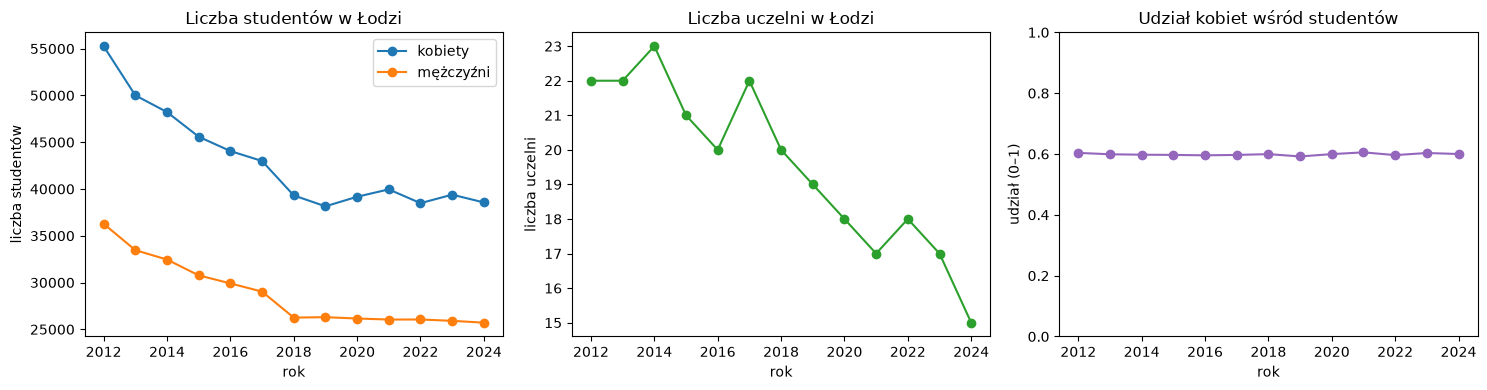

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
ax = axes[0]
ax.plot(szeroka.index, szeroka["kobiety"], marker="o", label="kobiety")
ax.plot(szeroka.index, szeroka["mężczyźni"], marker="o", label="mężczyźni")
ax.set_title("Liczba studentów w Łodzi")
ax.set_xlabel("rok")
ax.set_ylabel("liczba studentów")
ax.legend()

# TODO: wykres 2 — uczelnie
ax = axes[1]
ax.plot(szeroka.index, szeroka["uczelnie"], marker="o", color="tab:green")
ax.set_title("Liczba uczelni w Łodzi")
ax.set_xlabel("rok")
ax.set_ylabel("liczba uczelni")

# TODO: wykres 3 — udział kobiet
ax = axes[2]
ax.plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", color="tab:purple")
ax.set_ylim(0, 1)
ax.set_title("Udział kobiet wśród studentów")
ax.set_xlabel("rok")
ax.set_ylabel("udział (0–1)")

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* otóż, liczba studentów w Łodzi spadła o około 30%, a absolwentów aż o 41%. Liczba uczelni również spadła z 22 do 15. Udział kobiet został stały. Takie najbardziej nagły spadek był w latach 2012-2018, a od 2019 ruku liczby są mniej więcej stabilne.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Przeciętne miesięczne wynagrodzenia brutto ogółem · **link:** https://otwarte.miasto.lodz.pl/dataset/przecietne-miesieczne-wynagrodzenia-brutto-ogolem · **data pobrania:** 27.10.2026


In [10]:
# TODO: wczytanie i przegląd Twojego zbioru
# Nazwa: Przeciętne miesięczne wynagrodzenia brutto ogółem.csv
# Link: https://otwarte.miasto.lodz.pl/dataset/przecietne-miesieczne-wynagrodzenia-brutto-ogolem
# Data: 27.10.2026
PLIK_LODZ_MY = "przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv"
upewnij_sie_ze_jest(PLIK_LODZ_MY)

# with open(PLIK_LODZ_MY, encoding="utf-8") as f:
#     for _ in range(5):
#         print(f.readline().rstrip())
# df_my = pd.read_csv(PLIK_LODZ, sep=";")

df_my = pd.read_csv(PLIK_LODZ_MY, decimal=",", sep=";", encoding="utf-8")
df_my.nunique()
wyn = df_my.set_index("rok")["wartość"].rename("wynagrodzenie")



Plik przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv jest na miejscu.


count     23.00
mean    4138.14
std     1764.46
min     2102.42
25%     2850.11
50%     3710.91
75%     4977.16
max     8621.77
Name: wynagrodzenie, dtype: float64
310.0878987072041
rok
2002     NaN
2003    3.00
2004    6.00
2005    4.70
2006    4.10
2007    7.90
2008   11.30
2009    5.20
2010    2.70
2011    5.70
2012    4.10
2013    4.00
2014    3.40
2015    5.50
2016    4.50
2017    5.50
2018    7.10
2019    8.30
2020    6.50
2021   10.00
2022    9.40
2023   13.90
2024   14.20
Name: wynagrodzenie, dtype: float64
Największy wzrost: 2024 Najmniejszy: 2010
Braki w kolumnach:
id         0
rok        0
wartość    0
zmienne    0
dtype: int64
Zduplikowane lata: False
Lata ciągłe, bez luk: True
Zmiana 2002→2024 [%]: 310.1


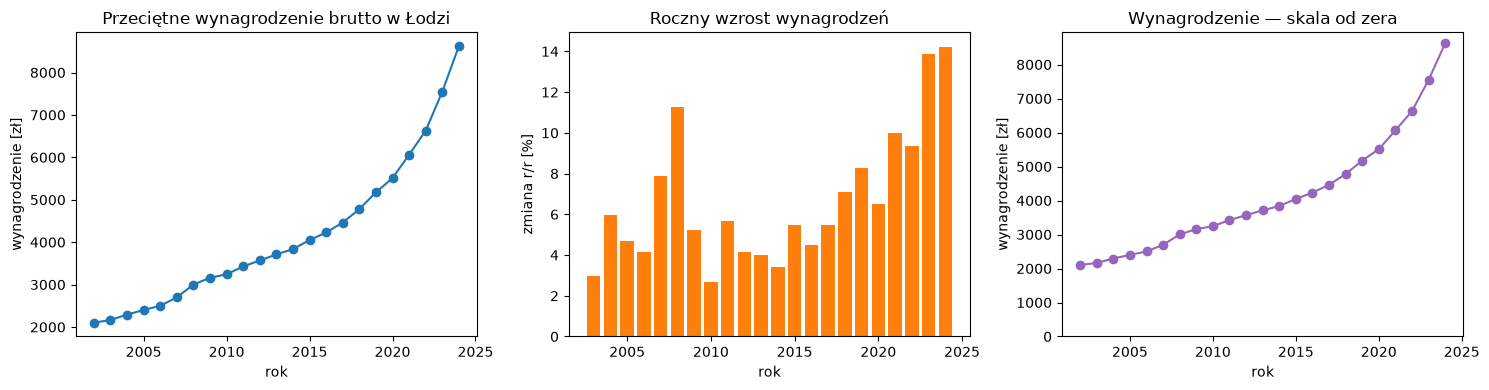

In [11]:
# TODO: przekształcenia, statystyki i wykresy
print(wyn.describe())                                   # mean, std, min, max, quartiles
print((wyn.loc[2024] - wyn.loc[2002]) / wyn.loc[2002] * 100)   # total change in %, like 1.4

wzrost = wyn.pct_change() * 100
print(wzrost.round(1))
print("Największy wzrost:", wzrost.idxmax(), "Najmniejszy:", wzrost.idxmin())

print("Braki w kolumnach:")
print(df_my.isna().sum())
print("Zduplikowane lata:", df_my["rok"].duplicated().any())
print("Lata ciągłe, bez luk:", (wyn.index.to_series().diff() == 1)[1:].all())
print("Zmiana 2002→2024 [%]:", round((wyn.loc[2024] - wyn.loc[2002]) / wyn.loc[2002] * 100, 1))


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.plot(wyn.index, wyn, marker="o")
ax.set_title("Przeciętne wynagrodzenie brutto w Łodzi")
ax.set_xlabel("rok")
ax.set_ylabel("wynagrodzenie [zł]")

ax = axes[1]
ax.bar(wzrost.index, wzrost, color="tab:orange")
ax.set_title("Roczny wzrost wynagrodzeń")
ax.set_xlabel("rok")
ax.set_ylabel("zmiana r/r [%]")

ax = axes[2]
ax.plot(wyn.index, wyn, marker="o", color="tab:purple")
ax.set_ylim(0, None)
ax.set_title("Wynagrodzenie — skala od zera")
ax.set_xlabel("rok")
ax.set_ylabel("wynagrodzenie [zł]")

plt.tight_layout()
plt.show()


✍️ **Wnioski:** Przeciętne wynagrodzenie brutto w Łodzi wzrosło z 2102 zł (2002) do 8622 zł (2024), czyli o ok. 310%, średnio ok. 6,6% rocznie. Wzrost był nominalnie dodatni w każdym roku; najwolniejszy w 2010 (2,7%, po kryzysie 2008–09), a najszybszy w latach 2021–2024 (10–14% r/r), co w dużej mierze odzwierciedla wysoką inflację. Bez uwzględnienia inflacji nie można stwierdzić, o ile realnie wzrosła siła nabywcza.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [12]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

          age     bmi  avg_glucose_level
count 3000.00 3000.00            3000.00
mean    45.25   26.29             134.00
std     20.83   15.88             181.27
min      0.67   -5.20             -21.40
25%     28.00   21.28              85.59
50%     49.00   24.70             101.40
75%     63.00   28.88             127.43
max     80.00  105.60            1254.60


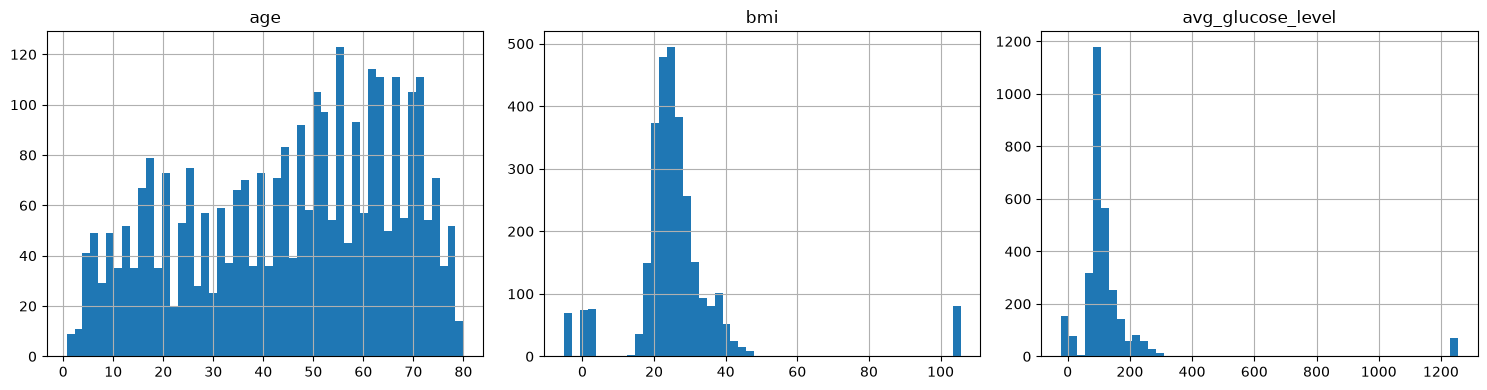

In [13]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
print(pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(bins=50, figsize=(15, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:*

| Zmienna | Min. możliwe | Maks. możliwe | W danych (min – max) | Ocena |
|---|---|---|---|---|
| `age` | 0 lat  | ok. 122 lata (rekord: Jeanne Calment) | 0,67 – 80 | wszystko możliwe |
| `bmi` | ok. 10 (skrajne wyniszczenie, poniżej ~12 zagrożenie życia) | ok. 60–70 w praktyce klinicznej (pojedyncze rekordy >150) | −5,2 – 105,6 | ujemne niemożliwe; >60 praktycznie niespotykane |
| `avg_glucose_level` | ok. 20–40 mg/dl (poniżej — śpiączka hipoglikemiczna) | pojedynczy pomiar do ok. 1000–2000 mg/dl (śpiączka, rekord ~2650), ale *średni* poziom rzadko przekracza ~400–500 | −21,4 – 1254,6 | ujemne niemożliwe; średnia >800 niemożliwa |

Wniosek: wiek jest w całości poprawny, a minimum i maksimum BMI oraz glukozy leżą poza zakresem fizjologicznym — to błędy danych, nie rzadcy pacjenci.

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [14]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 60) & pacjenci["bmi"].notna()
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800) & pacjenci["avg_glucose_level"].notna()
zly_wiek = ~pacjenci["age"].between(0, 120) & pacjenci["age"].notna()

# TODO: liczebności
print("Niemożliwe bmi:     ", zle_bmi.sum())
print("Niemożliwa glukoza: ", zla_glukoza.sum())
print("Niemożliwy wiek:    ", zly_wiek.sum())
print("Pacjenci z co najmniej jedną niemożliwą wartością:", (zle_bmi | zla_glukoza | zly_wiek).sum())

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

Niemożliwe bmi:      300
Niemożliwa glukoza:  300
Niemożliwy wiek:     0
Pacjenci z co najmniej jedną niemożliwą wartością: 560


          age     bmi  avg_glucose_level
count 3000.00 2700.00            2700.00
mean    45.25   26.12             116.84
std     20.83    5.84              44.45
min      0.67   13.57              44.76
25%     28.00   21.94              89.47
50%     49.00   24.98             103.09
75%     63.00   28.85             127.84
max     80.00   47.62             332.91
Braki: {'age': 0, 'bmi': 300, 'avg_glucose_level': 300}


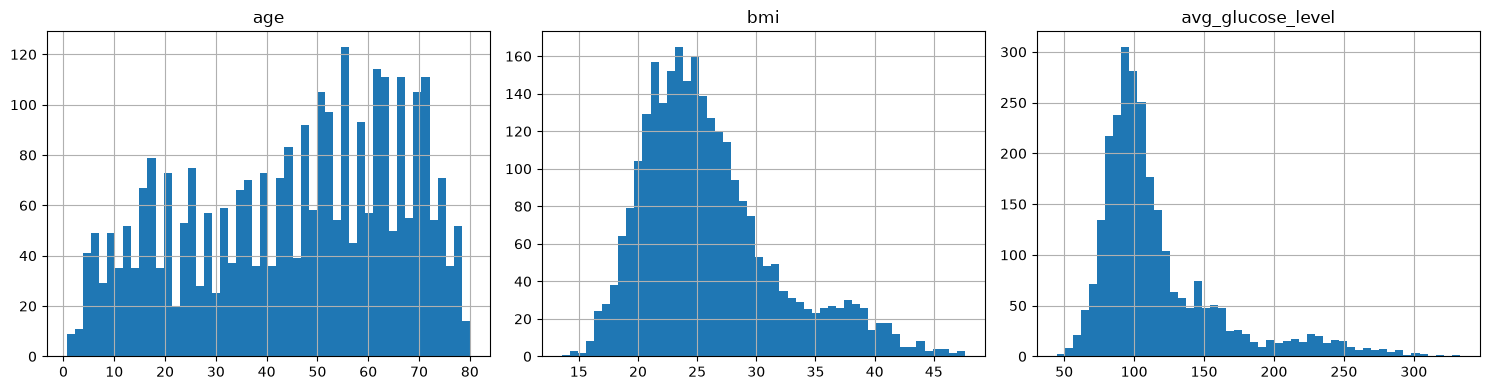

In [15]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
print(pacjenci[LICZBOWE].describe())
print("Braki:", pacjenci[LICZBOWE].isna().sum().to_dict())

pacjenci[LICZBOWE].hist(bins=50, figsize=(15, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

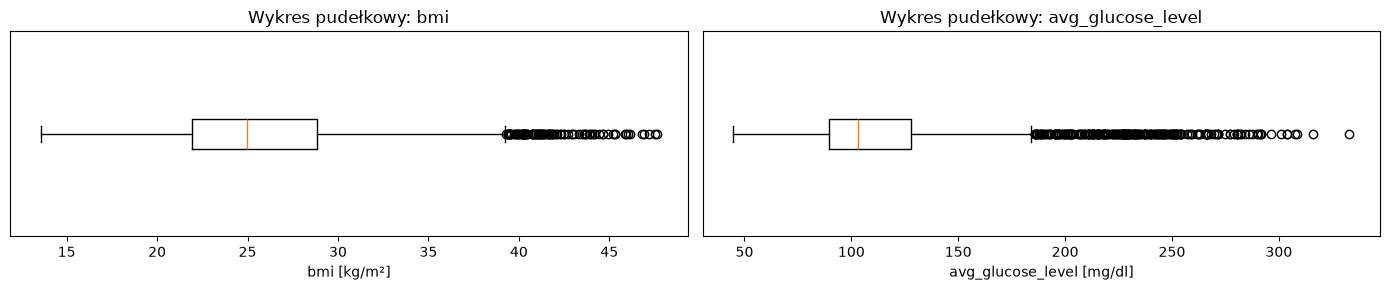

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
for ax, kol, jedn in zip(axes, ["bmi", "avg_glucose_level"], ["kg/m²", "mg/dl"]):
    ax.boxplot(pacjenci[kol].dropna(), orientation="horizontal")
    ax.set_title(f"Wykres pudełkowy: {kol}")
    ax.set_xlabel(f"{kol} [{jedn}]")
    ax.set_yticks([])

plt.tight_layout()
plt.show()

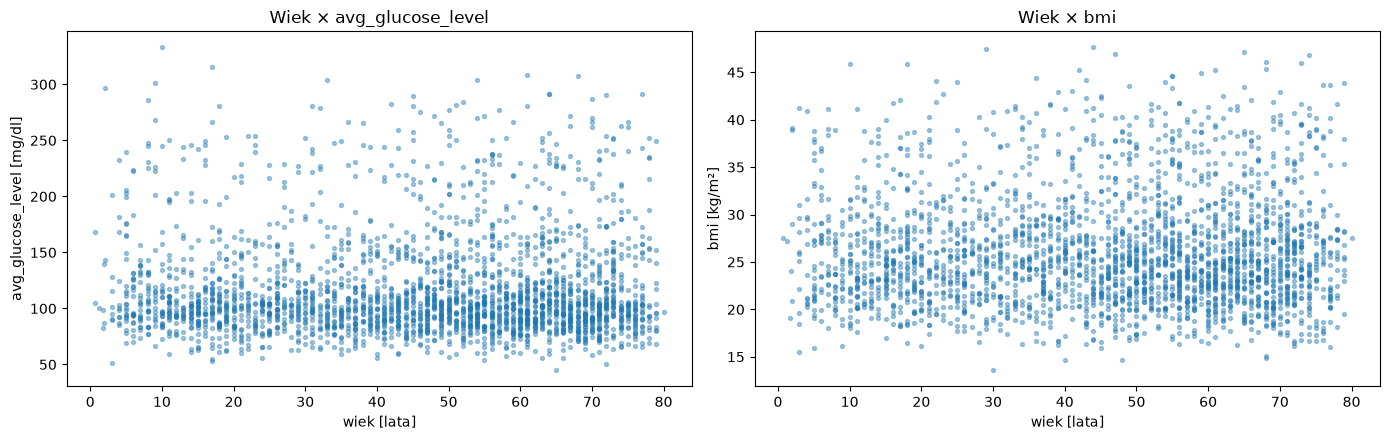

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
for ax, kol, jedn in zip(axes, ["avg_glucose_level", "bmi"], ["mg/dl", "kg/m²"]):
    ax.scatter(pacjenci["age"], pacjenci[kol], s=8, alpha=0.4)
    ax.set_title(f"Wiek × {kol}")
    ax.set_xlabel("wiek [lata]")
    ax.set_ylabel(f"{kol} [{jedn}]")

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*
1. Więcej punktów poza wąsem ma glukoza (235 vs 100 dla BMI). W obu zmiennych leżą one **tylko po prawej stronie** (wartości wysokie) — rozkłady są prawoskośne, długi ogon idzie w górę, a dolnych odstających brak.
2. Wysokie wartości glukozy (>200 mg/dl) występują w **każdym wieku**, od dzieci po 80-latków — nie skupiają się w jednej grupie. 10-latek z glukozą ~330 mg/dl jest fizjologicznie *możliwy* (np. nieleczona cukrzyca typu 1 / kwasica ketonowa), więc to raczej **rzadki przypadek do weryfikacji** niż pewny błąd — mieści się w zakresie możliwym z kroku 1. Jednak średnia glukoza >300 u dziecka jest mało prawdopodobna, więc warto go oznaczyć flagą.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [18]:
def maska_iqr(s, k=1.5):
    # TODO
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)   # NaN w porównaniu daje False

def maska_z(s, prog=3):
    # TODO
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    # TODO
    med = s.median()
    mad = (s - med).abs().median()
    return (0.6745 * (s - med) / mad).abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [19]:
# TODO: tabela porównawcza `porownanie`
porownanie = pd.DataFrame({
    "IQR 1,5": [maska_iqr(pacjenci[k]).sum() for k in LICZBOWE],
    "IQR 3": [maska_iqr(pacjenci[k], k=3).sum() for k in LICZBOWE],
    "z-score": [maska_z(pacjenci[k]).sum() for k in LICZBOWE],
    "MAD": [maska_mad(pacjenci[k]).sum() for k in LICZBOWE],
    "skośność": [pacjenci[k].skew() for k in LICZBOWE],
}, index=LICZBOWE)
porownanie

,"IQR 1,5",IQR 3,z-score,MAD,skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Glukoza jest silnie prawoskośna (skośność 1,80) — ma główny szczyt ok. 100 mg/dl i długi ogon z drugim „garbem” ok. 200–250 mg/dl (podgrupa pacjentów z wysoką glukozą). Metody oparte na różnych założeniach wyznaczają więc bardzo różne progi: IQR 1,5 i MAD (oparte na medianie i kwartylach, czyli na wąskim środku rozkładu) oznaczają prawie cały ogon — 235 i 223 obserwacje; IQR 3 jest łagodniejszy (81); z-score (62) używa średniej i odchylenia standardowego, które sam ogon zawyża (std ≈ 44), przez co próg $\bar{x} + 3s$ wypada wysoko — wartości odstające „maskują się” nawzajem, a założenie normalności nie jest spełnione. Wiek jest rozłożony dość równomiernie w ograniczonym przedziale 0–80 lat (skośność −0,33, brak ogonów), więc żadna wartość nie leży daleko od środka i żadna metoda nic nie wykrywa.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

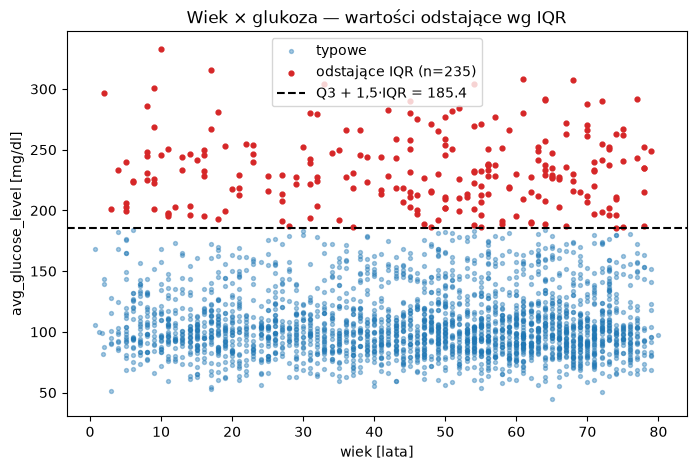

Punkty nad linią: 235 | pod dolnym wąsem: 0


In [20]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
glu = pacjenci["avg_glucose_level"]
odst = maska_iqr(glu)
q1, q3 = glu.quantile(0.25), glu.quantile(0.75)
gorna = q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pacjenci.loc[~odst, "age"], glu[~odst], s=8, alpha=0.4, label="typowe")
ax.scatter(pacjenci.loc[odst, "age"], glu[odst], s=12, color="tab:red",
           label=f"odstające IQR (n={odst.sum()})")
ax.axhline(gorna, color="black", linestyle="--", label=f"Q3 + 1,5·IQR = {gorna:.1f}")
ax.set_title("Wiek × glukoza — wartości odstające wg IQR")
ax.set_xlabel("wiek [lata]")
ax.set_ylabel("avg_glucose_level [mg/dl]")
ax.legend()
plt.show()

print("Punkty nad linią:", (glu > gorna).sum(), "| pod dolnym wąsem:", (glu < q1 - 1.5 * (q3 - q1)).sum())

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów [%]:
                   odsetek  liczba
avg_glucose_level                 
glukoza odstająca    21.70     235
pozostali            21.10    2465


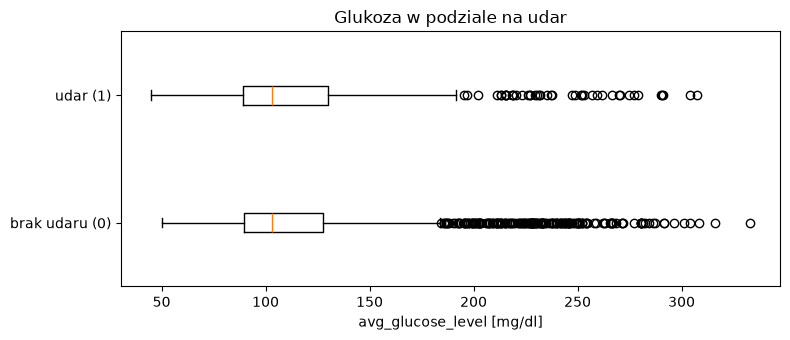

In [21]:
# TODO: odsetek udarów w obu grupach (tylko pacjenci ze znaną glukozą)
znana = pacjenci["avg_glucose_level"].notna()
grupa = odst[znana].map({True: "glukoza odstająca", False: "pozostali"})
print("Odsetek udarów [%]:")
print(pacjenci.loc[znana].groupby(grupa)["stroke"].agg(odsetek=lambda s: s.mean() * 100, liczba="size"))

# TODO: boxplot glukozy w podziale na stroke
fig, ax = plt.subplots(figsize=(8, 3.5))
dane = [pacjenci.loc[pacjenci["stroke"] == s, "avg_glucose_level"].dropna() for s in (0, 1)]
ax.boxplot(dane, orientation="horizontal", tick_labels=["brak udaru (0)", "udar (1)"])
ax.set_title("Glukoza w podziale na udar")
ax.set_xlabel("avg_glucose_level [mg/dl]")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie. To prawdziwe (możliwe fizjologicznie) wartości, a w rzeczywistości wysoka glukoza jest jednym z czynników ryzyka udaru — usunięcie ich wycięłoby z danych właśnie tę informację, której model potrzebuje, i zaniżyłoby zakres, na którym model działa. W tych syntetycznych danych odsetek udarów jest w obu grupach prawie taki sam (21,7% vs 21,1%), a rozkłady glukozy dla `stroke = 0/1` niemal się pokrywają, ale to tym bardziej nie uzasadnia usuwania. Lepiej je zostawić, ewentualnie zlogarytmować glukozę lub dodać flagę „wysoka glukoza”.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [22]:
# TODO: tabela krzyżowa
print(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))
print()
print(pacjenci.groupby("work_type")["age"].agg(["min", "max"]))   # dodatkowo: wiek w każdej grupie

# TODO: maski
dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")

print("Dziecko pali:", dziecko_pali.sum(), "| Maluch-student:", maluch_student.sum())
pacjenci.loc[dziecko_pali | maluch_student, ["patient_id", "age", "work_type", "smoking_status"]]

smoking_status  Unknown  formerly smoked  never smoked  smokes
work_type                                                     
Govt_job             16               63            94      67
Never_worked          1               30            36      35
Private              76              440           585     445
Self-employed        18              137           166     131
children             17                0           274      15
student              22               67           190      75

                min   max
work_type                
Govt_job      30.00 77.00
Never_worked  31.00 79.00
Private       15.00 80.00
Self-employed  9.00 79.00
children       0.67 14.00
student        1.80 29.00
Dziecko pali: 15 | Maluch-student: 1


,patient_id,age,work_type,smoking_status
52,A582477,1.80,student,formerly smoked
111,A678646,9.00,children,smokes
290,A844121,13.00,children,smokes
336,A135365,12.00,children,smokes
352,A810636,14.00,children,smokes
361,A843508,2.00,children,smokes
578,A161666,3.00,children,smokes
600,A623587,10.00,children,smokes
613,A892803,13.00,children,smokes
741,A560170,13.00,children,smokes


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Nie. Metody jednowymiarowe (IQR, z-score, MAD) analizują każdą cechę w pełnej izolacji od pozostałych i służą wyłącznie do badania rozkładu zmiennych ilościowych (liczbowych). W analizowanych przypadkach pojedyncze wartości są całkowicie typowe i poprawne (np. wiek ≤ 3 lata to normalny wiek małego dziecka, kategoria „children” lub „student” to poprawne statusy zatrudnienia, a „smokes” to poprawny status palenia). Anomalia ujawnia się wyłącznie na poziomie **relacji logicznej** między dwiema zmiennymi (kategoryczna × kategoryczna lub numeryczna × kategoryczna) — czego jednowymiarowe metody statystyczne ze swej natury nie są w stanie wykryć.


## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [23]:
from scipy.stats import chi2

# TODO: X, Z, d2, prog
# 1. Kolumny LICZBOWE bez braków
X = pacjenci[LICZBOWE].dropna()

# 2. Standaryzacja i kwadrat odległości euklidesowej od środka
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)

# 3. Próg chi2 dla 3 cech na poziomie kwantyla 0.99
prog = chi2.ppf(0.99, df=len(LICZBOWE))
odstajacy = d2 > prog

print(f"Próg chi² (p=0.99, df={len(LICZBOWE)}): {prog:.4f}")
print(f"Liczba pacjentów odstających (d² > próg): {odstajacy.sum()} / {len(X)}")

# 4. Która cecha ma największy udział w d² u tych pacjentów
kwadraty_z = Z.loc[odstajacy] ** 2
glowna_cecha = kwadraty_z.idxmax(axis=1)
print("\nNajwiększy wkład w d² u pacjentów odstających:")
print(glowna_cecha.value_counts())


Próg chi² (p=0.99, df=3): 11.3449
Liczba pacjentów odstających (d² > próg): 73 / 2440

Największy wkład w d² u pacjentów odstających:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Liczba odstających po zlogarytmowaniu glukozy: 31 (spadek z 73)

Największy wkład w d²_log po transformacji:
bmi                  22
avg_glucose_level     9
Name: count, dtype: int64


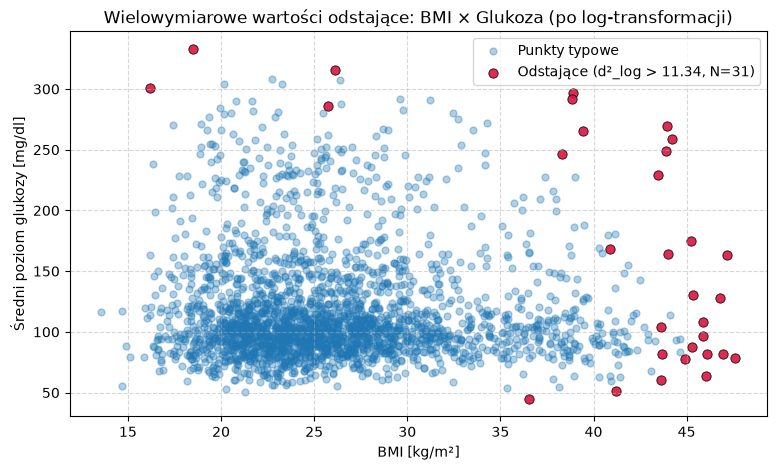

In [24]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])

Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odstajacy_log = d2_log > prog

print(f"Liczba odstających po zlogarytmowaniu glukozy: {odstajacy_log.sum()} (spadek z {odstajacy.sum()})")
print("\nNajwiększy wkład w d²_log po transformacji:")
print((Z_log.loc[odstajacy_log] ** 2).idxmax(axis=1).value_counts())

# TODO: wykres punktowy
plt.figure(figsize=(9, 5))
plt.scatter(X.loc[~odstajacy_log, "bmi"], X.loc[~odstajacy_log, "avg_glucose_level"],
            c="tab:blue", alpha=0.35, s=25, label="Punkty typowe")
plt.scatter(X.loc[odstajacy_log, "bmi"], X.loc[odstajacy_log, "avg_glucose_level"],
            c="crimson", alpha=0.9, s=45, edgecolor="black", linewidth=0.6,
            label=f"Odstające (d²_log > {prog:.2f}, N={odstajacy_log.sum()})")

plt.xlabel("BMI [kg/m²]")
plt.ylabel("Średni poziom glukozy [mg/dl]")
plt.title("Wielowymiarowe wartości odstające: BMI × Glukoza (po log-transformacji)")
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Nie, w tej sytuacji odległość Mahalanobisa dałaby praktycznie identyczne rezultaty jak wystandaryzowana odległość euklidesowa. Odległość Mahalanobisa definiowana jest jako $d_M^2 = (x - \mu)^T \Sigma^{-1} (x - \mu)$, gdzie $\Sigma$ jest macierzą kowariancji. Ponieważ korelacje pomiędzy cechami są bliskie zeru ($|r| < 0{,}025$), macierz kowariancji jest macierzą w przybliżeniu diagonalną. W takiej sytuacji macierz odwrotna $\Sigma^{-1}$ zawiera na przekątnej jedynie odwrotności wariancji poszczególnych zmiennych ($1/s_j^2$), a elementy pozaprzekątne znikają. Wzór redukuje się więc bezpośrednio do sumy kwadratów z-score'ów: $\sum (x_j - \bar{x}_j)^2 / s_j^2 = d^2$. Odległość Mahalanobisa przynosi istotną wartość dodaną dopiero wtedy, gdy pomiędzy zmiennymi istnieją silne zależności liniowe (obracając i skalując elipsoidę rozrzutu danych).


### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [25]:
# TODO (dla chętnych)
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
iso_labels = iso.fit_predict(X_log)  # -1 dla anomalii, 1 dla punktów typowych
iso_odstajace = pd.Series(iso_labels == -1, index=X_log.index)

wspolne = iso_odstajace & odstajacy_log

print(f"Isolation Forest wykrył odstających:  {iso_odstajace.sum()}")
print(f"Odległość d²_log wykryła odstających:  {odstajacy_log.sum()}")
print(f"Wspólne wskazania obu metod:           {wspolne.sum()} ({wspolne.sum() / iso_odstajace.sum():.1%} pokrycia IF)")


Isolation Forest wykrył odstających:  25
Odległość d²_log wykryła odstających:  31
Wspólne wskazania obu metod:           19 (76.0% pokrycia IF)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [26]:
# TODO: ramka flagi
flagi = pd.DataFrame(index=oryginal.index)

# Krok 1: Niemożliwe wartości fizjologiczne
flagi["niemozliwa_wartosc"] = zle_bmi | zla_glukoza | zly_wiek

# Krok 2: Wartości odstające glukozy wg IQR 1.5
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"], k=1.5)

# Krok 3: Nielogiczne kombinacje kategorii
flagi["nielogiczna_kategoria"] = dziecko_pali | maluch_student

# Krok 4: Nietypowe kombinacje liczb (d2_log > próg chi2; pacjenci bez obliczonej odległości -> False)
flagi["odlegly_od_srodka"] = False
flagi.loc[odstajacy_log.index, "odlegly_od_srodka"] = odstajacy_log

print("Liczba pacjentów z poszczególnymi flagami anomalii:")
print(flagi.sum())
print("-" * 45)
print(f"Pacjenci z co najmniej jedną flagą: {flagi.any(axis=1).sum()} / {len(flagi)} ({flagi.any(axis=1).mean():.1%})")


Liczba pacjentów z poszczególnymi flagami anomalii:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
---------------------------------------------
Pacjenci z co najmniej jedną flagą: 806 / 3000 (26.9%)


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | **zamiana na NaN** (lub usunięcie / imputacja) | Są to ewidentne błędy rejestracji bądź aparatury (np. ujemne BMI/glukoza), niemające racji bytu biologicznego i wypaczające statystyki. |
| wysoka glukoza (IQR) | **zostawić + flaga lub transformacja log** | Wartości te są fizjologicznie możliwe i niosą kluczową informację o ciężkiej cukrzycy oraz podwyższonym ryzyku udaru; usunięcie ich zniekształciłoby badanie. |
| nielogiczne kategorie | **poprawić (jeśli znana reguła) / NaN / flaga** | Wynikają z pomyłki wprowadzania danych (np. 2-latek jako student lub niemowlę palące); pojedyncze wartości są poprawne, lecz ich kombinacja jest fikcyjna. |
| odlegli od środka | **flaga informacyjna / inspekcja wielowymiarowa** | Pacjenci o rzadkich, skrajnych profilach wielocechowych; warto zachować o nich wiedzę dzięki fladze, unikając bezpodstawnego usuwania cennych obserwacji. |
